# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
numbers = list(range(10))  # список для shuffle

def gen():
    """Одне генерування: випадкове число + перемішаний (свіжий) список."""
    n = random.randint(1, 100)
    lst = numbers.copy()
    random.shuffle(lst)
    return n, lst

print("--- ДО set_seed() (двічі) ---")
for i in range(2):
    print(f"спроба {i+1}:", gen())

set_seed()
print("\nSeed зафіксовано:", SEED)

print("\n--- ПІСЛЯ set_seed() перед КОЖНИМ генеруванням (двічі) ---")
for i in range(2):
    set_seed()
    print(f"спроба {i+1}:", gen())

print("\n--- Без проміжних викликів set_seed() (двічі) ---")
for i in range(2):
    print(f"спроба {i+1}:", gen())


--- ДО set_seed() (двічі) ---
спроба 1: (11, [6, 3, 7, 2, 8, 5, 9, 0, 1, 4])
спроба 2: (38, [4, 5, 2, 9, 0, 7, 6, 8, 1, 3])

Seed зафіксовано: 42

--- ПІСЛЯ set_seed() перед КОЖНИМ генеруванням (двічі) ---
спроба 1: (82, [7, 3, 2, 8, 5, 6, 9, 4, 0, 1])
спроба 2: (82, [7, 3, 2, 8, 5, 6, 9, 4, 0, 1])

--- Без проміжних викликів set_seed() (двічі) ---
спроба 1: (76, [4, 3, 2, 9, 5, 1, 7, 8, 0, 6])
спроба 2: (92, [5, 1, 9, 0, 2, 4, 7, 3, 6, 8])


**Пояснення до вправи 1.**

`set_seed()` встановлює початковий стан (seed = 42) генератора псевдовипадкових чисел. Генератор не «справді» випадковий: кожне наступне число визначається його поточним станом, а seed задає цей стан.

- **До `set_seed()`** seed береться з системи (час, ентропія ОС), тому два виклики дають різні числа й різні перестановки, а кожен запуск комірки дає ще інший результат.
- **Після `set_seed()` перед кожним генеруванням** генератор щоразу повертається в один і той самий стан, тому обидві спроби дають **однакові** результати (те саме число і ту саму перестановку). Результат ще й повторюється між запусками ноутбука.
- **Без проміжного `set_seed()`** стан генератора після першої спроби вже змінився, тому друга спроба дає **інше** значення, ніж перша. Але вся послідовність відтворювана: після нового `set_seed()` вона повториться точно так само.

Тобто seed робить випадковість **відтворюваною**, а не прибирає її. Усередині послідовності числа все одно різні. Саме тому в ML фіксують seed: щоб експерименти (ініціалізація ваг, спліт даних) можна було повторити. Для shuffle важливо ще й починати з однакового списку (тому в `gen()` копіюється `numbers`), бо перемішування вже перемішаного списку дало б інший результат навіть із тим самим seed.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [7]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape, zeros_arr.dtype)
print(sevens_arr, sevens_arr.shape, sevens_arr.dtype)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [8]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [9]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity, "ndim =", identity.ndim)
print(random_ints, "ndim =", random_ints.ndim)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] ndim = 2
[[6 3 7]
 [4 6 9]
 [2 6 7]] ndim = 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [10]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [11]:
arr = np.arange(1, 13)

matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [12]:
df = pd.DataFrame({
    "name": ["Олена", "Іван", "Марія", "Андрій", "Софія", "Дмитро", "Тетяна", "Максим"],
    "score": [92, 78, 85, 67, 90, 74, 88, 95],
})

top = df[df["score"] > 80].sort_values("score", ascending=False)
print(top)


     name  score
7  Максим     95
0   Олена     92
4   Софія     90
6  Тетяна     88
2   Марія     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [13]:
df["grade"] = np.select([df["score"] >= 90, df["score"] >= 75], ["A", "B"], default="C")
print(df)


     name  score grade
0   Олена     92     A
1    Іван     78     B
2   Марія     85     B
3  Андрій     67     C
4   Софія     90     A
5  Дмитро     74     C
6  Тетяна     88     B
7  Максим     95     A


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [14]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t, zeros_t.shape, zeros_t.dtype)
print(sevens_t, sevens_t.shape, sevens_t.dtype)


tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [15]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [16]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list, from_list.shape, from_list.dtype, from_list.ndim)
print(random_t, random_t.shape, random_t.dtype, random_t.ndim)


tensor([[1, 2],
        [3, 4]]) torch.Size([2, 2]) torch.int64 2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]]) torch.Size([3, 3]) torch.float32 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [17]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("autograd  dy/dx =", x.grad.item())
print("аналітично 2*x  =", 2 * n)
assert abs(x.grad.item() - 2 * n) < 1e-6


autograd  dy/dx = 10.0
аналітично 2*x  = 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [18]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for step in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

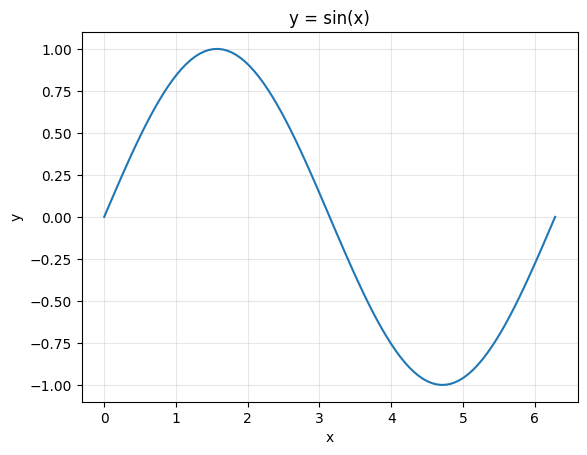

In [19]:
xs = np.linspace(0, 2 * np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.title("y = sin(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(alpha=0.3)
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

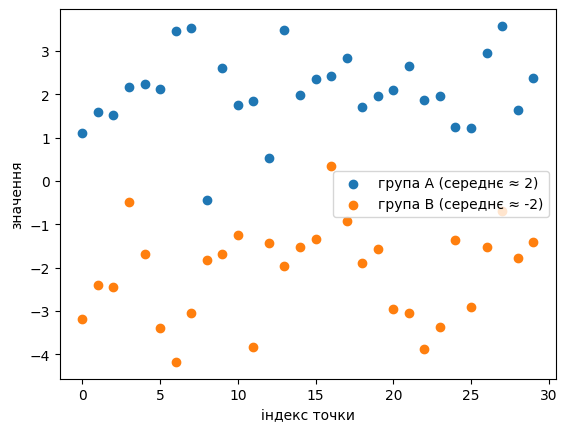

In [20]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.scatter(range(30), group_a, color="C0", label="група A (середнє ≈ 2)")
plt.scatter(range(30), group_b, color="C1", label="група B (середнє ≈ -2)")
plt.xlabel("індекс точки")
plt.ylabel("значення")
plt.legend()
plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [21]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

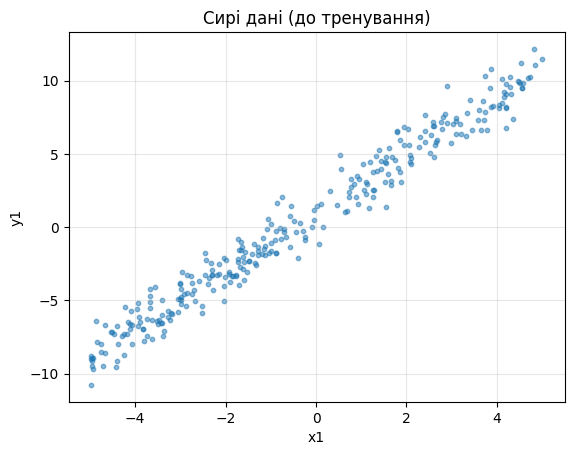

In [22]:
plt.scatter(x1.numpy(), y1.numpy(), s=10, alpha=0.5)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.grid(alpha=0.3)
plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [23]:
set_seed()
perm = torch.randperm(TASK1_N)
x_shuf, y_shuf = x1[perm], y1[perm]

n_train = int(0.70 * TASK1_N)
n_val = int(0.15 * TASK1_N)

x_train1, y_train1 = x_shuf[:n_train], y_shuf[:n_train]
x_val1, y_val1 = x_shuf[n_train:n_train + n_val], y_shuf[n_train:n_train + n_val]
x_test1, y_test1 = x_shuf[n_train + n_val:], y_shuf[n_train + n_val:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [24]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=43.316730  w=1.5235 (true 2.0)  b=0.0181 (true 1.0)
epoch   30  loss=1.000557  w=1.9719 (true 2.0)  b=0.9505 (true 1.0)
epoch   60  loss=0.997888  w=1.9749 (true 2.0)  b=0.9956 (true 1.0)
epoch   90  loss=0.997882  w=1.9750 (true 2.0)  b=0.9978 (true 1.0)
epoch   99  loss=0.997882  w=1.9750 (true 2.0)  b=0.9978 (true 1.0)


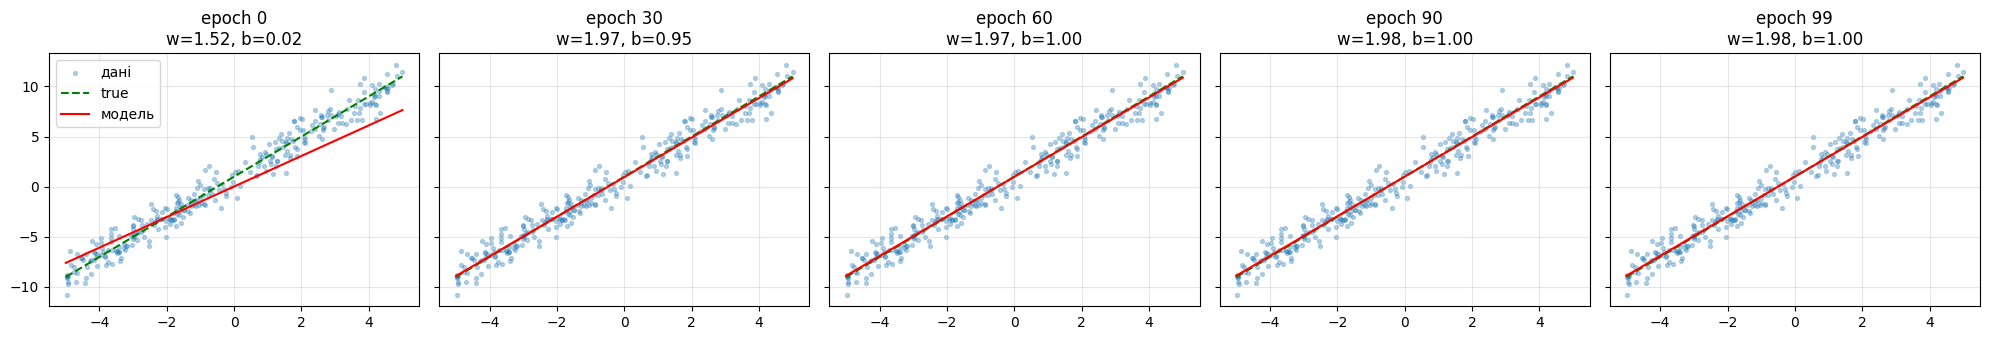

In [25]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Вправа 20. Власний сценарій: години навчання → бал за контрольну

**Сценарій.** Студент щодня присвячує підготовці до контрольної від 0 до 8 годин. Припускаємо, що бал (0-100) залежить від кількості годин лінійно:

$$\text{score} = w \cdot \text{hours} + b + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, \sigma^2)$$

- $w = 7$: кожна додаткова година навчання на день додає в середньому ~7 балів. Це правдоподібно: 8 годин дають приріст у ~56 балів, тобто від «нічого не знаю» до «добре підготовлений».
- $b = 35$: бал студента, який зовсім не готувався. Зі здоровим глуздом і спробою вгадати частину тестових питань виходить ~35, а не 0.
- $\sigma = 5$: шум, бо на результат впливають ще сон, стрес, складність варіанта тощо.

Тоді максимум без шуму: $7 \cdot 8 + 35 = 91$, що вкладається в шкалу 0-100.

In [26]:
HOURS_TRUE_W = 7.0
HOURS_TRUE_B = 35.0
HOURS_NOISE_STD = 5.0
HOURS_N = 400
HOURS_MAX = 8.0

DATASET_PATH = os.path.join(ARTIFACT_DIR, "dataset.csv")
MODEL_PATH = os.path.join(ARTIFACT_DIR, "model.pt")


def generate_dataset(n, w, b, noise_std, x_max, seed=SEED):
    """Генерує дані y = w*x + b + шум і повертає DataFrame."""
    g = torch.Generator().manual_seed(seed)
    x = torch.rand(n, 1, generator=g) * x_max
    y = w * x + b + noise_std * torch.randn(n, 1, generator=g)
    return pd.DataFrame({"hours": x.squeeze(1).numpy(), "score": y.squeeze(1).numpy()})


def save_dataset(df, *paths):
    for p in paths:
        df.to_csv(p, index=False)
        print("CSV збережено:", p)


def load_dataset(path):
    df = pd.read_csv(path)
    x = torch.tensor(df[["hours"]].values, dtype=torch.float32)
    y = torch.tensor(df[["score"]].values, dtype=torch.float32)
    return x, y


def split_data(x, y, train=0.70, val=0.15, seed=SEED):
    """Перемішує і ділить на train/val/test."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(x), generator=g)
    x, y = x[perm], y[perm]
    n_train, n_val = int(train * len(x)), int(val * len(x))
    return ((x[:n_train], y[:n_train]),
            (x[n_train:n_train + n_val], y[n_train:n_train + n_val]),
            (x[n_train + n_val:], y[n_train + n_val:]))


@torch.no_grad()
def evaluate(model, x, y, loss_fn=None):
    loss_fn = loss_fn or torch.nn.MSELoss()
    pred = model(x)
    mse = loss_fn(pred, y).item()
    r2 = 1 - ((y - pred) ** 2).sum().item() / ((y - y.mean()) ** 2).sum().item()
    return mse, r2


def train_model(train_data, val_data, lr=0.01, epochs=2000, log_every=400):
    """Тренує Linear(1, 1) за тим самим патерном, що й у вправі 19."""
    (x_tr, y_tr), (x_va, y_va) = train_data, val_data
    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()
    history = {"train": [], "val": []}

    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(x_tr), y_tr)
        loss.backward()
        optimizer.step()

        val_loss, _ = evaluate(model, x_va, y_va, loss_fn)
        history["train"].append(loss.item())
        history["val"].append(val_loss)

        if epoch % log_every == 0 or epoch == epochs - 1:
            print(f"epoch {epoch:5d}  train={loss.item():8.3f}  val={val_loss:8.3f}  "
                  f"w={model.weight.item():.3f}  b={model.bias.item():.3f}")
    return model, history


In [27]:
set_seed()

# 1. Генеруємо дані та зберігаємо в CSV (на Drive і поруч із ноутбуком)
df_hours = generate_dataset(HOURS_N, HOURS_TRUE_W, HOURS_TRUE_B, HOURS_NOISE_STD, HOURS_MAX)
save_dataset(df_hours, DATASET_PATH, "dataset.csv")
print(df_hours.head())

# 2. Читаємо CSV назад і ділимо на train/val/test
x_h, y_h = load_dataset(DATASET_PATH)
train_h, val_h, test_h = split_data(x_h, y_h)
print(f"train/val/test: {len(train_h[0])}/{len(val_h[0])}/{len(test_h[0])}")

# 3. Тренуємо
hours_model, history_h = train_model(train_h, val_h, lr=0.01, epochs=2000)

# 4. Перевіряємо на test
test_mse, test_r2 = evaluate(hours_model, *test_h)
print(f"\nНавчені:  w={hours_model.weight.item():.3f}, b={hours_model.bias.item():.3f}")
print(f"Справжні: w={HOURS_TRUE_W}, b={HOURS_TRUE_B}")
print(f"TEST: MSE={test_mse:.3f} (шум σ²={HOURS_NOISE_STD**2:.1f}), R²={test_r2:.3f}")


CSV збережено: /content/drive/MyDrive/ai_systems/lab1/dataset.csv
CSV збережено: dataset.csv
      hours      score
0  7.058154  84.530571
1  7.320032  80.919479
2  3.062910  52.639400
3  7.674445  86.683586
4  3.123586  61.676926
train/val/test: 280/60/60
epoch     0  train=3516.208  val=1477.960  w=5.711  b=1.973
epoch   400  train=  30.106  val=  27.760  w=7.457  b=32.390
epoch   800  train=  27.284  val=  25.589  w=6.930  b=35.142
epoch  1200  train=  27.259  val=  25.556  w=6.880  b=35.403
epoch  1600  train=  27.259  val=  25.555  w=6.876  b=35.428
epoch  1999  train=  27.259  val=  25.555  w=6.875  b=35.430

Навчені:  w=6.875, b=35.430
Справжні: w=7.0, b=35.0
TEST: MSE=20.390 (шум σ²=25.0), R²=0.907


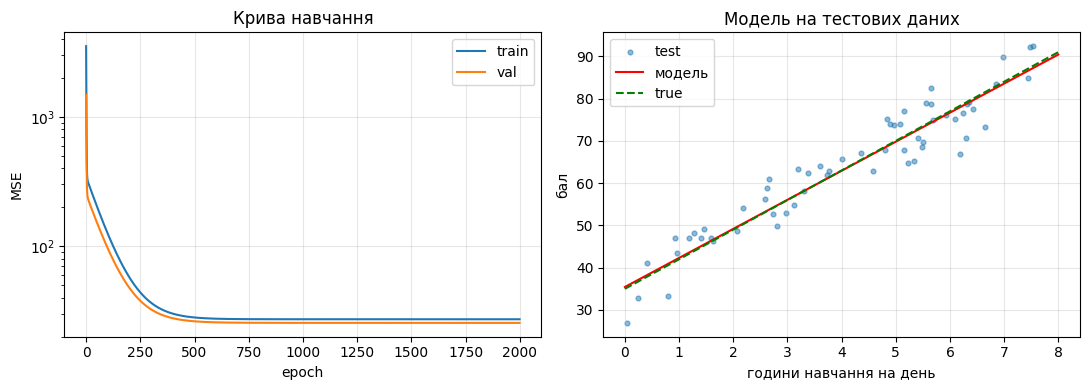

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history_h["train"], label="train")
axes[0].plot(history_h["val"], label="val")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("MSE"); axes[0].set_title("Крива навчання")
axes[0].legend(); axes[0].grid(alpha=0.3)

xl = torch.linspace(0, HOURS_MAX, 100).unsqueeze(1)
with torch.no_grad():
    yl = hours_model(xl)
axes[1].scatter(*[t.numpy() for t in test_h], s=12, alpha=0.5, label="test")
axes[1].plot(xl.numpy(), yl.numpy(), "r-", label="модель")
axes[1].plot(xl.numpy(), HOURS_TRUE_W * xl.numpy() + HOURS_TRUE_B, "g--", label="true")
axes[1].set_xlabel("години навчання на день"); axes[1].set_ylabel("бал")
axes[1].set_title("Модель на тестових даних"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [29]:
torch.save(hours_model.state_dict(), MODEL_PATH)   # Google Drive
torch.save(hours_model.state_dict(), "model.pt")    # копія поруч із ноутбуком (для репозиторію)
print("Модель збережено:", MODEL_PATH, "та ./model.pt")

# перевірка: завантажуємо назад і порівнюємо передбачення
check = torch.nn.Linear(1, 1)
check.load_state_dict(torch.load(MODEL_PATH))
check.eval()
assert torch.allclose(check(x_h), hours_model(x_h))
print("Перевірка завантаження пройшла успішно")


Модель збережено: /content/drive/MyDrive/ai_systems/lab1/model.pt та ./model.pt
Перевірка завантаження пройшла успішно


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [30]:
!pip install -q gradio

In [31]:
import gradio as gr

# завантажуємо модель, збережену у вправі 21
app_model = torch.nn.Linear(1, 1)
app_model.load_state_dict(torch.load(MODEL_PATH))
app_model.eval()

def predict_score(hours):
    with torch.no_grad():
        score = app_model(torch.tensor([[float(hours)]])).item()
    return round(min(max(score, 0), 100), 1)  # бал обмежуємо шкалою 0-100

demo = gr.Interface(
    fn=predict_score,
    inputs=gr.Slider(0, 8, value=4, step=0.1, label="Години навчання на день"),
    outputs=gr.Number(label="Прогнозований бал за контрольну"),
    title="Години навчання → бал",
    description="Лінійна регресія, навчена на синтетичних даних.",
)
demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d84a6b47833c6bb345.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```